# Classifying 200 bird species with k-Nearest Neighbours

**Dataset:** CUB-200-2011 (Wah et al., 2011), [Kaggle copy](https://www.kaggle.com/datasets/wenewone/cub2002011)
**Task:** predict a bird's species (200 classes) from 312 yes/no visual attributes annotated for each photo
**Model:** k-nearest neighbours (KNN) · **Split:** the dataset's official `train_test_split.txt`

| Step | Section | Course link |
|---|---|---|
| Look at the dataset | 2 | Lecture 3: getting to know your data |
| Prepare and check the data | 3 | Lecture 3: data preparation |
| Training and test data | 4 | Lecture 5: holdout, stratification |
| Baselines: majority class and the lab's first KNN | 5 | Lecture 3, Iris lab (Tutorial) |
| Choose k, distance and weighting | 6 | Lecture 5: cross-validation for parameters |
| Final evaluation on the test set | 7 | Lecture 6: evaluation measures |
| Error analysis | 8 | Lecture 6: confusion matrix |
| Summary | 9 | |

## 1. Setup

In [26]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score,
                             top_k_accuracy_score, roc_auc_score, confusion_matrix)

RANDOM_STATE = 42
ROOT = Path.cwd() if (Path.cwd() / 'notebooks').exists() else Path.cwd().parent   # repo folder
RAW_DIRS = [ROOT / 'data' / 'raw', ROOT / 'CUB_200_2011']    # where the Kaggle download may be unzipped
RESULTS = ROOT / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

# Stratified 10-fold cross-validation on the TRAINING set only (Lecture 5)
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

## 2. The dataset

Files used from the Kaggle download:

| File | Contents |
|---|---|
| `classes.txt` | the 200 species names |
| `images.txt` | the 11,788 photos |
| `image_class_labels.txt` | the species of each photo (the answer) |
| `train_test_split.txt` | the official split: 1 = training, 0 = test |
| `attributes.txt` | the 312 attribute names, e.g. `has_bill_shape::cone`, in 28 body-part groups |
| `attributes/image_attribute_labels.txt` | for every photo and attribute: present (0/1) and the annotator's certainty (1 not visible, 2 guessing, 3 probably, 4 definitely) |

Each photo becomes one row of 312 zeros and ones: a point in a 312-dimensional space.
Each body-part question, such as wing colour, is spread over several 0/1 columns (1-of-k representation).

In [27]:
def find_file(name):
    """Find a dataset file anywhere under the data folders (the Kaggle zip's nesting can vary)."""
    for root in RAW_DIRS:
        hits = sorted(root.rglob(name)) if root.exists() else []
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{name} not found under {[str(r) for r in RAW_DIRS]} - '
                            'run scripts/download_data.py or unzip the Kaggle download into data/raw/')


def read_ws(name, cols):
    """Read a whitespace-separated CUB file with no header."""
    return pd.read_csv(find_file(name), sep=r'\s+', header=None, names=cols)


def load_cub():
    """Returns (meta, present, certainty, attributes, repaired_rows).
    meta: one row per image (species, bird group, split, photo path)
    present: 0/1 attribute matrix, one row per image, one column per attribute
    certainty: the annotator's certainty for each value (1 not visible ... 4 definitely)"""
    classes = read_ws('classes.txt', ['class_id', 'class_name'])
    labels = read_ws('image_class_labels.txt', ['image_id', 'class_id'])
    split = read_ws('train_test_split.txt', ['image_id', 'is_train'])
    images = read_ws('images.txt', ['image_id', 'path'])
    attributes = read_ws('attributes.txt', ['attr_id', 'attr_name'])
    attributes[['group', 'value']] = attributes.attr_name.str.split('::', expand=True)

    # One line per (image, attribute): image_id attr_id is_present certainty time.
    # 606 lines have a stray extra field before the time; the first four fields are always correct.
    ial = pd.read_csv(find_file('image_attribute_labels.txt'), sep=r'\s+', header=None,
                      names=['image_id', 'attr_id', 'is_present', 'certainty', 'f5', 'f6'])
    repaired = int(ial.f6.notna().sum())
    ial = ial[['image_id', 'attr_id', 'is_present', 'certainty']].astype(int)

    names = attributes.set_index('attr_id').attr_name
    present = ial.pivot(index='image_id', columns='attr_id', values='is_present').rename(columns=names)
    certainty = ial.pivot(index='image_id', columns='attr_id', values='certainty').rename(columns=names)
    present.columns.name = certainty.columns.name = None

    meta = (labels.merge(classes, on='class_id').merge(split, on='image_id').merge(images, on='image_id')
                  .set_index('image_id').sort_index())
    meta['species'] = meta.class_name.str.split('.', n=1).str[1].str.replace('_', ' ')
    meta['group'] = meta.species.str.split().str[-1]          # e.g. "American Crow" -> "Crow"
    photo_dir = find_file('images.txt').parent / 'images'
    meta['photo'] = [photo_dir / p for p in meta.path]
    return meta, present.loc[meta.index], certainty.loc[meta.index], attributes, repaired


t0 = time.time()
meta, present, certainty, attributes, repaired = load_cub()
print(f'loaded in {time.time() - t0:.0f}s')
print(f'{len(meta):,} photos | {meta.class_id.nunique()} species | {present.shape[1]} attributes '
      f'in {attributes.group.nunique()} body-part groups | {meta.group.nunique()} bird groups')

loaded in 6s
11,788 photos | 200 species | 312 attributes in 28 body-part groups | 70 bird groups


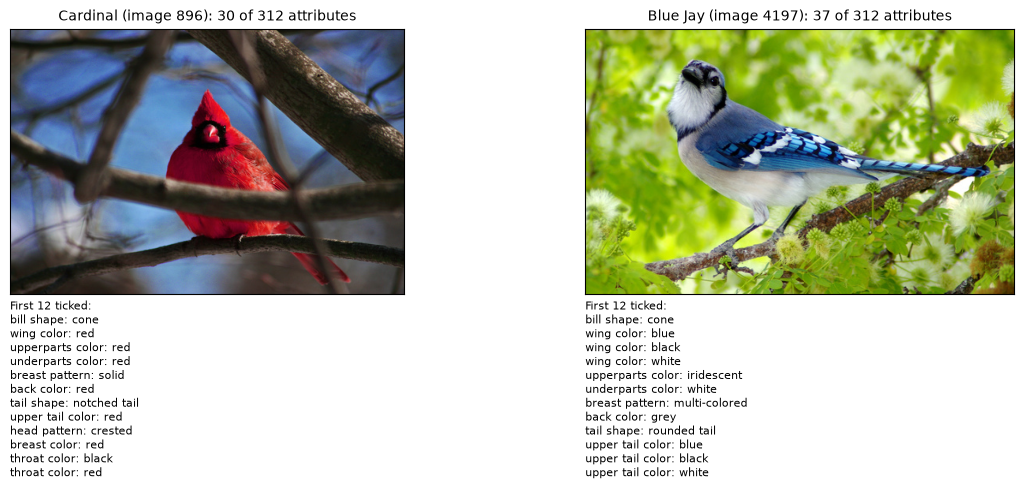

In [28]:
# Two example birds: their photo and the attributes ticked for them
def show_examples(names):
    picks = [meta.index[meta.species == n][0] for n in names if (meta.species == n).any()]
    picks = picks or list(meta.index[:2])
    fig, axes = plt.subplots(1, len(picks), figsize=(6 * len(picks), 4.5))
    for ax, img_id in zip(np.atleast_1d(axes), picks):
        row = meta.loc[img_id]
        if Path(row.photo).exists():
            ax.imshow(plt.imread(row.photo))
        ticked = present.columns[present.loc[img_id] == 1]
        short = [c.replace('has_', '').replace('::', ': ').replace('_', ' ') for c in ticked[:12]]
        ax.set_title(f'{row.species} (image {img_id}): {len(ticked)} of 312 attributes', fontsize=10)
        ax.set_xlabel('First 12 ticked:\n' + '\n'.join(short), fontsize=8, loc='left')
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()
    plt.savefig(FIGURES / 'knn_example_birds.png', dpi=150, bbox_inches='tight')
    plt.show()


show_examples(['Cardinal', 'Blue Jay'])

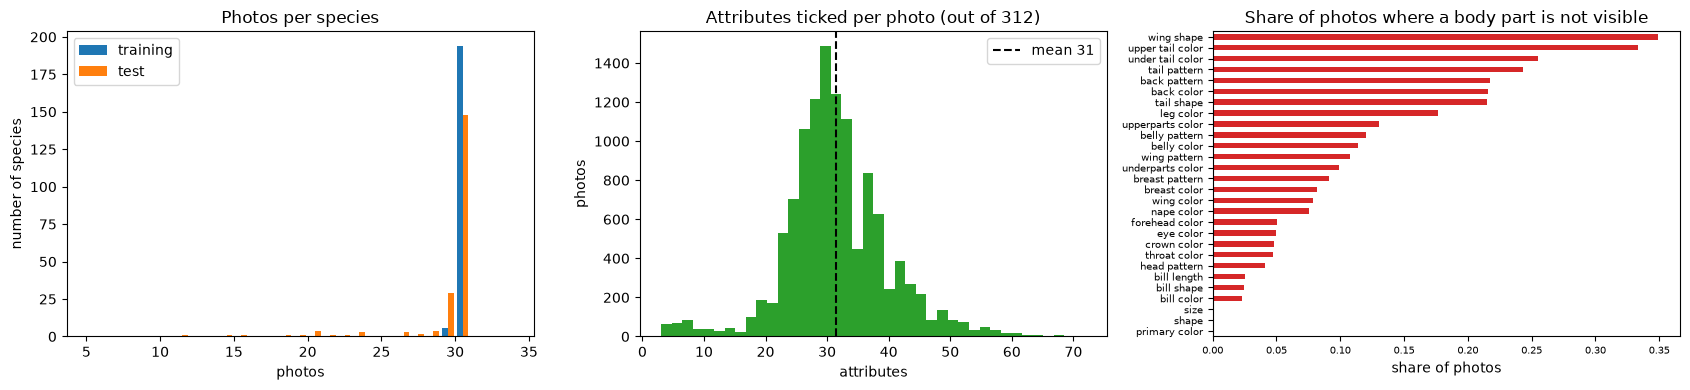

In [29]:
# The dataset at a glance
not_visible_share = (certainty == 1).T.groupby(attributes.set_index('attr_name').group).mean().T.mean()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
counts = meta.groupby(['class_id', 'is_train']).size().unstack()
axes[0].hist([counts[1], counts[0]], bins=range(5, 35), label=['training', 'test'])
axes[0].set(title='Photos per species', xlabel='photos', ylabel='number of species')
axes[0].legend()

per_photo = present.sum(axis=1)
axes[1].hist(per_photo, bins=40, color='tab:green')
axes[1].axvline(per_photo.mean(), color='black', ls='--', label=f'mean {per_photo.mean():.0f}')
axes[1].set(title='Attributes ticked per photo (out of 312)', xlabel='attributes', ylabel='photos')
axes[1].legend()

not_visible_share.rename(lambda g: g.replace('has_', '').replace('_', ' ')).sort_values().plot.barh(
    ax=axes[2], color='tab:red', fontsize=7)
axes[2].set(title='Share of photos where a body part is not visible', xlabel='share of photos', ylabel='')
plt.tight_layout()
plt.savefig(FIGURES / 'knn_dataset_overview.png', dpi=150, bbox_inches='tight')
plt.show()

> The three charts reveal that the dataset is relatively well-balanced for training (consistently around 29–30 photos per species), while the test set varies more broadly with about 11 to 30 photos per species. It exhibits high sparsity, as an average of only about 31 out of the 312 total attributes are ticked per photo, and it contains substantial hidden body parts, with specific features like wing shape and upper tail color being unobservable in over 30% of the images.

## 3. Data preparation checks

Look at the data critically, consider unusual data, check for missing data, and scale or normalise when needed.

In [30]:
keys = [row.tobytes() for row in present.to_numpy(np.uint8)]
same = pd.DataFrame({'key': keys, 'class_id': meta.class_id.values})
conflicts = same.groupby('key').class_id.nunique()
n_conflict_photos = int(same.key.isin(conflicts[conflicts > 1].index).sum())

checks = pd.DataFrame([
    ('Missing values (empty cells)', int(present.isna().sum().sum())),
    ('Values in the attribute table', str(sorted(int(v) for v in np.unique(present.values)))),
    ('Malformed lines repaired (extra field)', repaired),
    ('Rows per photo x attribute (should be 11,788 x 312)', f'{present.shape[0]:,} x {present.shape[1]}'),
    ('Attribute values marked "not visible" (stored as 0)', f'{(certainty == 1).values.mean():.1%}'),
    ('Photos sharing identical attributes with a DIFFERENT species', n_conflict_photos),
], columns=['check', 'result'])
checks

,check,result
0,Missing values (empty cells),0
1,Values in the attribute table,"[0, 1]"
2,Malformed lines repaired (extra field),606
3,"Rows per photo x attribute (should be 11,788 x...","11,788 x 312"
4,"Attribute values marked ""not visible"" (stored ...",10.7%
5,Photos sharing identical attributes with a DIF...,39


**Decisions for this notebook:**
- **"Not visible" values stay as 0** (treated as absent). This is the dataset's own encoding and the simplest baseline; other ways of handling these missing values are tested in `knn_improvements.ipynb`.
- **Photos with identical attributes (39 photos) but different species are kept**: they are real, separate photos. No model can get all of them right, which sets a small ceiling on accuracy.
- **No scaling or normalisation:** every feature is already 0 or 1, so no attribute can dominate the distance. Instance normalisation is related to the **cosine** distance tested in section 6, which compares the *pattern* of ticked attributes rather than how many were ticked.

## 4. Training and test data

The official split is a **holdout** set: the test photos play no part in building or tuning the model.
All choices (k, distance, weighting) are made with cross-validation on the training photos only.

In [31]:
X = present.astype(np.int8)
y = meta.class_id
is_train = meta.is_train == 1
X_train, X_test, y_train, y_test = X[is_train], X[~is_train], y[is_train], y[~is_train]

print('X_train shape:', X_train.shape, '| y_train shape:', y_train.shape)
print('X_test shape: ', X_test.shape, '| y_test shape: ', y_test.shape)
share = is_train.groupby(meta.class_id).mean()
print(f'Training share per species: {share.min():.0%} to {share.max():.0%} '
      f'(every species is in both sets, so the split is stratified)')

X_train shape: (5994, 312) | y_train shape: (5994,)
X_test shape:  (5794, 312) | y_test shape:  (5794,)
Training share per species: 49% to 73% (every species is in both sets, so the split is stratified)


## 5. Baselines: majority class and the lab's first KNN

**Majority classifier (ZeroR):** always predicts the most common species. Any useful model must beat it.
Then the same steps as the Iris lab: build, fit, predict, score.

In [32]:
from sklearn.dummy import DummyClassifier

majority = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f'Majority classifier test accuracy: {majority.score(X_test, y_test):.3f}')

Majority classifier test accuracy: 0.005


In [33]:
knn = KNeighborsClassifier(n_neighbors=1)   # create the model
knn.fit(X_train, y_train)                   # KNN only stores the training photos (lazy learning)
y_pred_k1 = knn.predict(X_test)             # each test photo gets the species of its nearest training photo

species_of = meta.drop_duplicates('class_id').set_index('class_id').species   # class number -> species name
pd.DataFrame({'actual species': meta.species.loc[y_test.index[:10]].values,
              'predicted species': species_of.loc[y_pred_k1[:10]].values})

,actual species,predicted species
0,Black footed Albatross,Brown Pelican
1,Black footed Albatross,Laysan Albatross
2,Black footed Albatross,Savannah Sparrow
3,Black footed Albatross,Western Grebe
4,Black footed Albatross,Black footed Albatross
5,Black footed Albatross,Indigo Bunting
6,Black footed Albatross,Lazuli Bunting
7,Black footed Albatross,Eared Grebe
8,Black footed Albatross,Gadwall
9,Black footed Albatross,Pelagic Cormorant


In [34]:
print('Test set score (k=1):           {:.3f}'.format(knn.score(X_test, y_test)))
print('Test set score (k=1), by hand:  {:.3f}'.format(np.mean(y_pred_k1 == y_test.values)))
knn11 = KNeighborsClassifier(n_neighbors=11).fit(X_train, y_train)
print('Test set score (k=11):          {:.3f}'.format(knn11.score(X_test, y_test)))
print('Training set score (k=1):       {:.3f}   <- resubstitution: hopelessly optimistic'
      .format(knn.score(X_train, y_train)))

Test set score (k=1):           0.294
Test set score (k=1), by hand:  0.294
Test set score (k=11):          0.314
Training set score (k=1):       0.999   <- resubstitution: hopelessly optimistic


> Our baseline KNN scores a test accuracy of 0.294 at k=1 and increases to 0.314 at k=11. The Iris dataset (in Lab week 1) gets exactly 97.0% accuracy for both k=1 and k=11. Iris features are clean and low-dimensional, with wide separations between a few classes. CUB has 200 species with massive overlap. At k=1, a single neighbor is often just a look-alike species from a different class. Increasing k averages out these random look-alike errors. However, making k too large will eventually blur the boundaries between distinct species.

## 6. Choosing k, distance and weighting

The parameter optimisation data can't be used for testing. Every combination below is scored with
stratified 10-fold cross-validation **on the training photos**; the best one is then retrained on all of them.

- **k:** how many neighbours vote
- **distance:** Euclidean and Manhattan, and cosine (compares the pattern of ticked attributes)
- **weighting:** every neighbour gets one vote (`uniform`), or closer neighbours count more (`distance`)

In [35]:
PARAM_GRID = {
    'n_neighbors': [1, 3, 5, 7, 9, 11, 15, 21, 31, 51],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'cosine'],
}
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}

t0 = time.time()
search = GridSearchCV(KNeighborsClassifier(), PARAM_GRID, cv=CV, scoring=SCORING, refit='accuracy',
                      n_jobs=-1, return_train_score=True).fit(X_train, y_train)
print(f'{len(search.cv_results_["params"])} combinations x 10 folds in {time.time() - t0:.0f}s')
print('Best settings:', search.best_params_)
print(f'Best cross-validated accuracy: {search.best_score_:.3f}')

res = pd.DataFrame(search.cv_results_)
res.sort_values('rank_test_accuracy')[['param_metric', 'param_n_neighbors', 'param_weights', 'mean_test_accuracy',
                                       'std_test_accuracy', 'mean_test_f1_macro']].head(8).round(4)

60 combinations x 10 folds in 561s
Best settings: {'metric': 'cosine', 'n_neighbors': 21, 'weights': 'distance'}
Best cross-validated accuracy: 0.353


,param_metric,param_n_neighbors,param_weights,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro
55,cosine,21,distance,0.3527,0.0135,0.3276
53,cosine,15,distance,0.3518,0.0111,0.3317
51,cosine,11,distance,0.3488,0.0099,0.3291
49,cosine,9,distance,0.3487,0.0151,0.3294
57,cosine,31,distance,0.3445,0.0102,0.3195
47,cosine,7,distance,0.3427,0.0068,0.3243
52,cosine,15,uniform,0.3423,0.0126,0.3183
54,cosine,21,uniform,0.3408,0.0143,0.3117


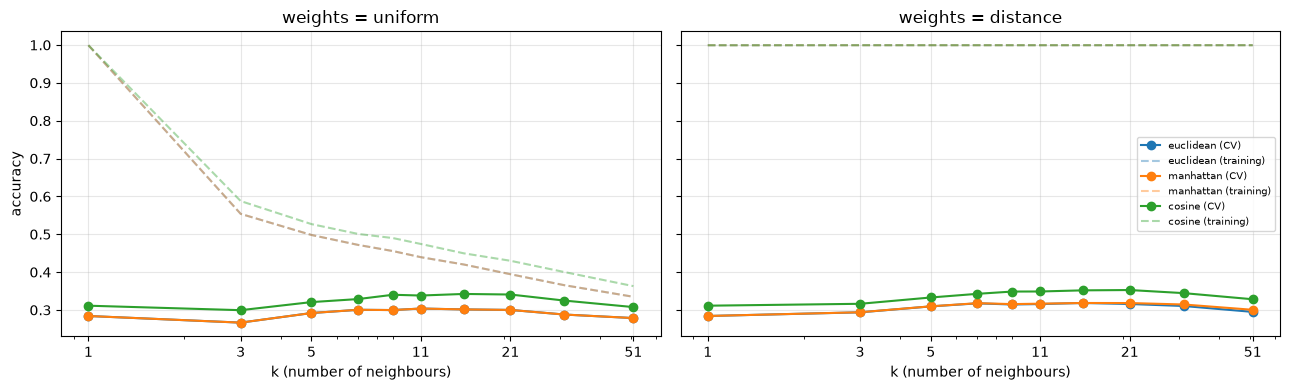

In [36]:
# Training accuracy (dashed) vs cross-validated accuracy (solid) as k grows
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, weights in zip(axes, ['uniform', 'distance']):
    for metric, colour in [('euclidean', 'tab:blue'), ('manhattan', 'tab:orange'), ('cosine', 'tab:green')]:
        r = res[(res.param_weights == weights) & (res.param_metric == metric)].sort_values('param_n_neighbors')
        ks = r.param_n_neighbors.astype(int)
        ax.plot(ks, r.mean_test_accuracy, 'o-', color=colour, label=f'{metric} (CV)')
        ax.plot(ks, r.mean_train_accuracy, '--', color=colour, alpha=0.4, label=f'{metric} (training)')
    ax.set(title=f'weights = {weights}', xlabel='k (number of neighbours)', xscale='log')
    ax.set_xticks([1, 3, 5, 11, 21, 51], ['1', '3', '5', '11', '21', '51'])
    ax.grid(alpha=0.3)
axes[0].set_ylabel('accuracy')
axes[1].legend(fontsize=7, loc='center right')
plt.tight_layout()
plt.savefig(FIGURES / 'knn_choosing_k.png', dpi=150, bbox_inches='tight')
plt.show()

> In the uniform weighting panel, training accuracy drops steadily from 100% as k grows, whereas in the distance weighting panel, training accuracy stays at about 100% (0.999) across all k values because scikit-learn gives the closest training sample all the vote when the distance is 0. For cosine distance with distance weighting, the cross-validation curve peaks at k = 21 with an accuracy of 0.353. After the peak, only the cross-validation curve gradually drops and levels off at a lower performance tier as the model enters the underfitting zone. 

## 7. Final evaluation on the test set

The test photos are used here for the first time. Measures extended to 200 classes:

| Measure | Meaning here |
|---|---|
| Success rate (accuracy) / error rate | share of test photos given the right / wrong species |
| Precision, recall, F-measure (macro) | computed for each species, then averaged so every species counts equally |
| Kappa | agreement with the true species, corrected for chance |
| Top-5 accuracy | the true species is among the model's 5 most-voted species |
| ROC AUC (macro, one species vs the rest) | how well the votes rank the true species above the others |

In [37]:
model = search.best_estimator_
t0 = time.time()
y_pred = model.predict(X_test)
predict_time = time.time() - t0
proba = model.predict_proba(X_test)


def evaluate(name, y_true, y_pred, proba, classes):
    acc = accuracy_score(y_true, y_pred)
    return {'model': name,
            'success rate': acc, 'error rate': 1 - acc,
            'precision (macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'recall (macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
            'F-measure (macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'kappa': cohen_kappa_score(y_true, y_pred),
            'top-5 accuracy': top_k_accuracy_score(y_true, proba, k=5, labels=classes),
            'ROC AUC (macro)': roc_auc_score(y_true, proba, multi_class='ovr', average='macro', labels=classes)}


classes = model.classes_
results = pd.DataFrame([
    evaluate('Majority class (ZeroR)', y_test, majority.predict(X_test), majority.predict_proba(X_test), classes),
    evaluate('KNN, k=1 (lab)', y_test, y_pred_k1, knn.predict_proba(X_test), classes),
    evaluate('KNN, k=11 (lab)', y_test, knn11.predict(X_test), knn11.predict_proba(X_test), classes),
    evaluate(f'KNN, tuned: {search.best_params_["metric"]}, k={search.best_params_["n_neighbors"]}, '
             f'{search.best_params_["weights"]}', y_test, y_pred, proba, classes),
]).set_index('model')

results.to_csv(RESULTS / 'knn_results.csv')
json.dump({'params': search.best_params_, 'cv_accuracy': search.best_score_,
           'test_accuracy': results.iloc[-1]['success rate']}, open(RESULTS / 'knn_best_params.json', 'w'), indent=1)
print(f'Prediction time for {len(X_test):,} test photos: {predict_time:.1f}s')
results.round(3)

Prediction time for 5,794 test photos: 1.0s


,success rate,error rate,precision (macro),recall (macro),F-measure (macro),kappa,top-5 accuracy,ROC AUC (macro)
model,,,,,,,,
Majority class (ZeroR),0.005,0.995,0.000,0.005,0.000,0.000,0.026,0.500
"KNN, k=1 (lab)",0.294,0.706,0.333,0.293,0.296,0.290,0.311,0.645
"KNN, k=11 (lab)",0.314,0.686,0.392,0.315,0.312,0.310,0.546,0.812
"KNN, tuned: cosine, k=21, distance",0.347,0.653,0.397,0.347,0.342,0.344,0.629,0.870


## 8. Error analysis

Where does the tuned KNN go wrong, and why?

In [38]:
group_of = meta.drop_duplicates('class_id').set_index('class_id').group
test = pd.DataFrame({'true': y_test.values, 'pred': y_pred}, index=y_test.index)
test['correct'] = test.true == test.pred
test['true_group'] = test.true.map(group_of)
test['pred_group'] = test.pred.map(group_of)
errors = test[~test.correct]
within = (errors.true_group == errors.pred_group).mean()
print(f'{len(errors):,} of {len(test):,} test photos are wrong ({len(errors) / len(test):.1%}).')
print(f'{within:.0%} of the mistakes confuse two species of the SAME bird group (e.g. two crows).')

3,783 of 5,794 test photos are wrong (65.3%).
28% of the mistakes confuse two species of the SAME bird group (e.g. two crows).


### 8.1 Most confused species pairs

In [39]:
pairs = (errors.groupby(['true', 'pred']).size().rename('count').reset_index()
               .sort_values('count', ascending=False).head(10))
pairs['true species'] = pairs.true.map(species_of)
pairs['predicted as'] = pairs.pred.map(species_of)
pairs['same group?'] = pairs.true.map(group_of) == pairs.pred.map(group_of)
pairs[['true species', 'predicted as', 'count', 'same group?']].reset_index(drop=True)

,true species,predicted as,count,same group?
0,Common Raven,American Crow,21,False
1,Fish Crow,American Crow,19,True
2,Pelagic Cormorant,American Crow,14,False
3,Blue winged Warbler,Prothonotary Warbler,14,True
4,Pine Warbler,Prothonotary Warbler,13,True
5,Blue Grosbeak,Indigo Bunting,13,False
6,California Gull,Western Gull,11,True
7,Boat tailed Grackle,American Crow,11,False
8,Common Tern,Artic Tern,10,True
9,Louisiana Waterthrush,Northern Waterthrush,10,True


### 8.2 Confusion matrix within one bird group

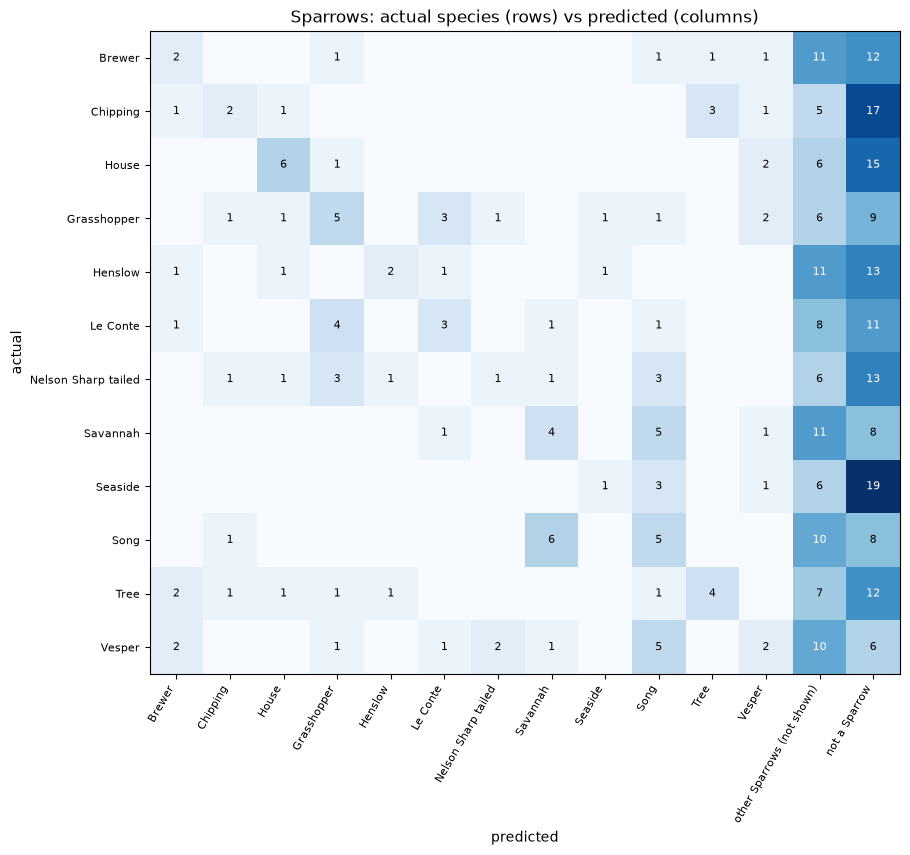

In [40]:
# The bird group with the most mistakes between its own species
group_counts = meta.drop_duplicates('class_id').group.value_counts()
candidates = errors[(errors.true_group == errors.pred_group) & errors.true_group.isin(group_counts[group_counts >= 3].index)]
focus = (candidates if len(candidates) else errors).true_group.value_counts().index[0]
in_group = [c for c in classes if group_of[c] == focus]
# Show at most 12 species of this group: the ones with the most test mistakes
worst = test[test.true.isin(in_group) & ~test.correct].true.value_counts().index[:12]
ids = sorted(worst) if len(worst) else in_group[:12]
sub = test[test.true.isin(ids)]
# Predictions outside the shown species: another species of the same group (-2), or a different group (-1)
outside = np.where(sub.pred.map(group_of) == focus, -2, -1)
cm = confusion_matrix(sub.true, sub.pred.where(sub.pred.isin(ids), outside), labels=ids + [-2, -1])[:len(ids)]
labels = [species_of[c].replace(' ' + focus, '') for c in ids]

fig, ax = plt.subplots(figsize=(2 + 0.6 * len(ids), 0.6 * len(ids) + 1.5))
ax.imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm):
    if v:
        ax.text(j, i, v, ha='center', va='center', fontsize=8, color='white' if v > cm.max() / 2 else 'black')
ax.set_xticks(range(len(ids) + 2), labels + [f'other {focus}s (not shown)', f'not a {focus}'], rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(ids)), labels, fontsize=8)
ax.set(title=f'{focus}s: actual species (rows) vs predicted (columns)', xlabel='predicted', ylabel='actual')
plt.tight_layout()
plt.savefig(FIGURES / 'knn_confusion_group.png', dpi=150, bbox_inches='tight')
plt.show()

In [41]:
# Which non-sparrow species are sparrows mistaken for?
outside = test[(test.true_group == focus) & (test.pred_group != focus)]
outside.pred.map(species_of).value_counts().head(8)

pred
Black and white Warbler    22
House Wren                 10
Loggerhead Shrike           9
Carolina Wren               9
Bewick Wren                 8
Eastern Towhee              8
Winter Wren                 8
Chuck will Widow            7
Name: count, dtype: int64

### 8.3 Accuracy by bird group and by species

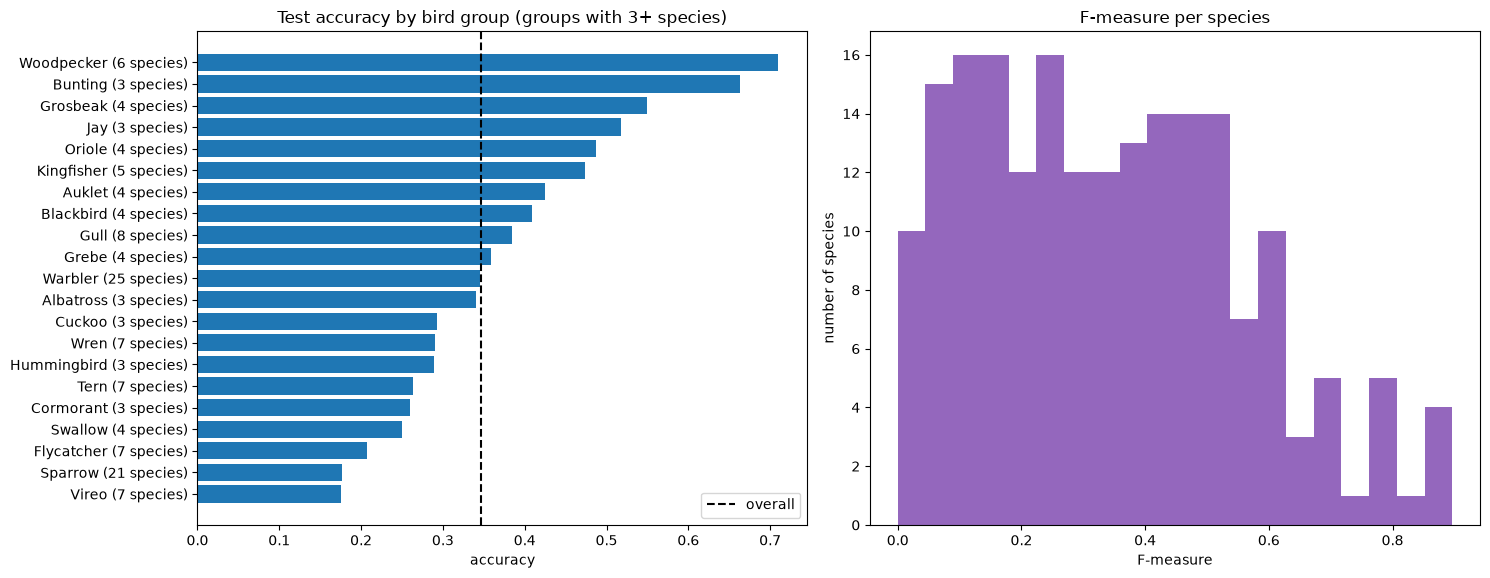

,best species,F (best),worst species,F (worst)
0,Pileated Woodpecker,0.897,Least Flycatcher,0.0
1,White breasted Kingfisher,0.877,Yellow bellied Flycatcher,0.0
2,Red headed Woodpecker,0.862,Slaty backed Gull,0.0
3,Rose breasted Grosbeak,0.862,Whip poor Will,0.0
4,Green Jay,0.807,Palm Warbler,0.0


In [42]:
by_group = test.groupby('true_group').agg(accuracy=('correct', 'mean'), photos=('correct', 'size'))
by_group['species'] = group_counts.reindex(by_group.index)
shown = by_group[by_group.species >= 3].sort_values('accuracy')

per_species = pd.Series(f1_score(test.true, test.pred, average=None, labels=classes),
                        index=species_of.loc[classes].values)

fig, axes = plt.subplots(1, 2, figsize=(15, max(4, 0.28 * len(shown))))
axes[0].barh([f'{g} ({n} species)' for g, n in zip(shown.index, shown.species)], shown.accuracy, color='tab:blue')
axes[0].axvline(test.correct.mean(), color='black', ls='--', label='overall')
axes[0].set(title='Test accuracy by bird group (groups with 3+ species)', xlabel='accuracy')
axes[0].legend()
axes[1].hist(per_species, bins=20, color='tab:purple')
axes[1].set(title='F-measure per species', xlabel='F-measure', ylabel='number of species')
plt.tight_layout()
plt.savefig(FIGURES / 'knn_accuracy_by_group.png', dpi=150, bbox_inches='tight')
plt.show()

pd.DataFrame({'best species': per_species.nlargest(5).index, 'F (best)': per_species.nlargest(5).values.round(3),
              'worst species': per_species.nsmallest(5).index, 'F (worst)': per_species.nsmallest(5).values.round(3)})

### 8.4 Does hidden information cause mistakes?

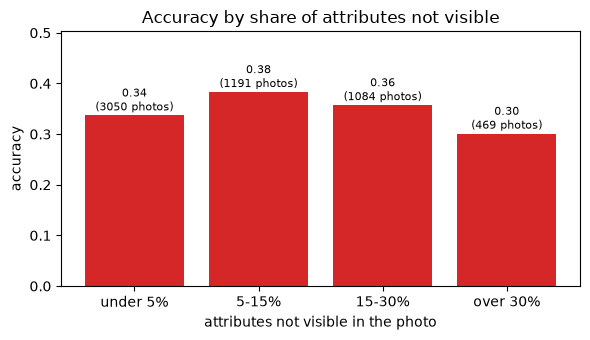

In [43]:
hidden = (certainty.loc[test.index] == 1).mean(axis=1)
bins = pd.cut(hidden, [-0.01, 0.05, 0.15, 0.30, 1.0], labels=['under 5%', '5-15%', '15-30%', 'over 30%'])
by_hidden = test.groupby(bins, observed=True).correct.agg(['mean', 'size'])
by_hidden.columns = ['accuracy', 'test photos']

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(by_hidden.index.astype(str), by_hidden.accuracy, color='tab:red')
for i, (a, n) in enumerate(zip(by_hidden.accuracy, by_hidden['test photos'])):
    ax.text(i, a + 0.01, f'{a:.2f}\n({n} photos)', ha='center', fontsize=8)
ax.set(title='Accuracy by share of attributes not visible', xlabel='attributes not visible in the photo',
       ylabel='accuracy', ylim=(0, max(by_hidden.accuracy) + 0.12))
plt.tight_layout()
plt.savefig(FIGURES / 'knn_hidden_vs_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.5 Looking at mistakes: a test photo and its nearest training photos

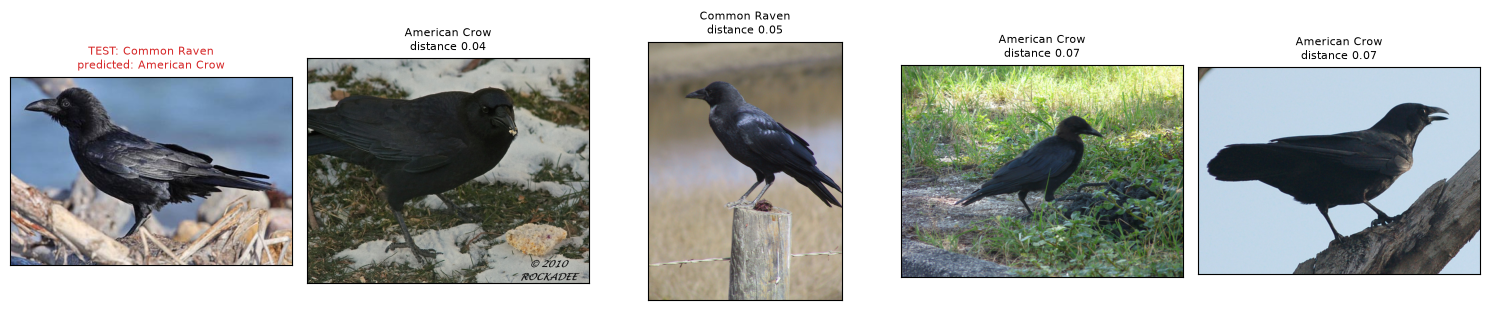

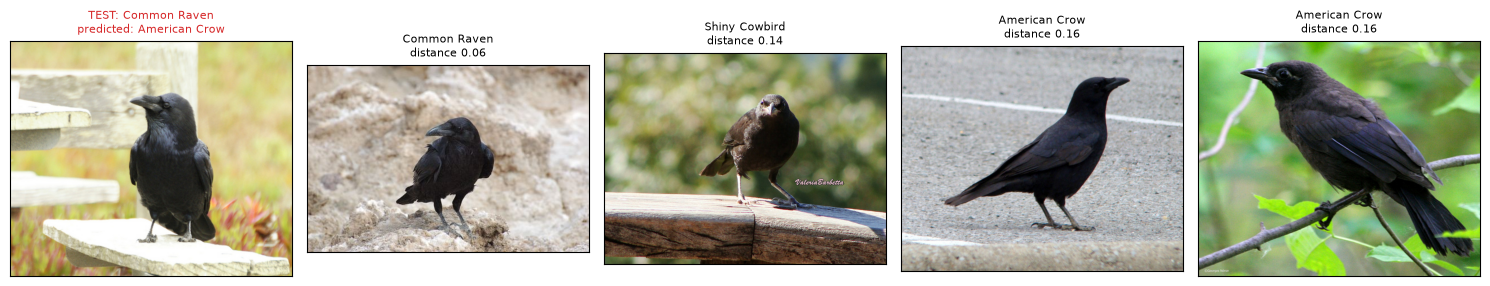

In [44]:
def show_neighbours(img_id, n=4):
    dist, idx = model.kneighbors(X_test.loc[[img_id]], n_neighbors=n)
    shown_ids = [img_id] + list(X_train.index[idx[0]])
    titles = [f'TEST: {meta.species[img_id]}\npredicted: {species_of[test.pred[img_id]]}'] + \
             [f'{meta.species[i]}\ndistance {d:.2f}' for i, d in zip(shown_ids[1:], dist[0])]
    fig, axes = plt.subplots(1, n + 1, figsize=(3 * (n + 1), 3.2))
    for ax, i, t in zip(axes, shown_ids, titles):
        if Path(meta.photo[i]).exists():
            ax.imshow(plt.imread(meta.photo[i]))
        ax.set_title(t, fontsize=8, color='tab:red' if i == img_id else 'black')
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()
    plt.show()
    return fig


top = pairs.iloc[0]
examples = errors[(errors.true == top.true) & (errors.pred == top.pred)].index[:2]
for k, img_id in enumerate(examples):
    fig = show_neighbours(img_id)
    fig.savefig(FIGURES / f'knn_mistake_{k + 1}.png', dpi=150, bbox_inches='tight')

> The model excels at identifying species with highly unique, bright colors or distinct shapes that do not overlap with other classes, such as the Pileated Woodpecker (0.897 F1 score) and Green Jay (0.807 F1 score), but fails completely on visually subtle or highly overlapping look-alikes like the Least Flycatcher and Yellow-bellied Flycatcher, which both score an F1 of 0.000. Our highest confusion occurs when the Common Raven is predicted as an American Crow (21 times), the Fish Crow is predicted as an American Crow (19 times), and the Blue-winged Warbler is predicted as a Prothonotary Warbler (14 times). Notably, the American Crow appears as the predicted class in four of the top ten confusion pairs, indicating a tendency to predict American Crow.

> A closer look at the Sparrows confusion matrix (Section 8.2, which highlights the 12 sparrows with the most mistakes out of 21) shows that sparrows are rarely classified correctly, with the diagonal mostly containing just 1 to 6 correct predictions out of about 30 photos per species. These mistakes split between other sparrows and outside groups: wrens dominate the external errors (with House, Carolina, Bewick, and Winter Wrens accounting for 35 total mistakes, likely because they are small, brown, and streaky like sparrows), alongside the Eastern Towhee (8) and Chuck-will's-widow (7). However, some anomalies emerge: the single biggest destination for sparrow errors is the Black-and-white Warbler (22 instances), alongside the Loggerhead Shrike (9), neither of which looks like a sparrow in a photograph. This likely happens because sparrows have many striped and streaked attribute ticks, and the Black-and-white Warbler shares similar binary descriptions (such as "striped," "streaked," black, and white). Once reduced to 0/1 attribute ticks, a streaky brown sparrow and a streaky black-and-white warbler can look similar to the model, suggesting that while many errors stem from true look-alike birds, others arise from look-alike attribute descriptions of birds that look quite different in reality.

> This aligns with our group-level findings: only 28% of mistakes stay within the same name-based bird group, meaning 72% cross into a different group. Partly, this happens because our name-based grouping is crude (for instance, a Common Raven predicted as an American Crow or a sparrow predicted as an Eastern Towhee counts as a cross-group mistake despite them being close relatives), but it also reflects how attribute look-alikes pull predictions across distinct groups. Furthermore, inspecting Section 8.5 (Looking at mistakes: a test photo and its nearest training photos) shows that for a misclassified Common Raven, its closest training photo (distance 0.04) was an American Crow, and 3 of its 4 nearest neighbours were American Crows (out of the 21 that vote). With distance weighting, these closest crows carry the most weight, which helps explain the wrong prediction. This suggests that most misclassifications stem from feature overlap rather than the KNN setup itself.

## 9. Summary

Results are saved to `results/knn_results.csv`; figures for slides are in `results/figures/`.

In [45]:
results[['success rate', 'F-measure (macro)', 'top-5 accuracy']].round(3)

,success rate,F-measure (macro),top-5 accuracy
model,,,
Majority class (ZeroR),0.005,0.000,0.026
"KNN, k=1 (lab)",0.294,0.296,0.311
"KNN, k=11 (lab)",0.314,0.312,0.546
"KNN, tuned: cosine, k=21, distance",0.347,0.342,0.629


> The tuned KNN model (using cosine distance, $k=21$, and distance weighting) achieves a success rate of 0.347, substantially outperforming the Majority class baseline (0.005) and the lab's initial $k=1$ model (0.294). Distance weighting and cosine distance likely won because they effectively handle the high-dimensional, sparse binary attribute space by giving closer neighbors more influence while measuring angular similarity between feature vectors. Error analysis reveals a nuanced two-part pattern: some errors stem from true visual look-alikes (such as crows and ravens, or sparrows and wrens), while others arise from look-alike attribute descriptions shared by birds that look quite different in reality (such as streaky sparrows misclassified as Black-and-white Warblers). This is further reflected by the finding that only 28% of mistakes stay within the same name-based bird group, meaning 72% cross groups. Additionally, performance exhibits a modest drop when a high proportion of body parts are obscured, going from 0.34 accuracy (in the under-5% missing attributes bin) down to 0.30 for the 469 photos in the over-30% missing attributes bin. For future work, extracting raw continuous features using a deep learning convolutional network (like ResNet) could capture richer visual signatures, though hidden body parts will still present a challenge if they are physically obscured.

> The study's primary limitations stem from methodological constraints, feature limitations, and computational overhead. Methodologically, relying on a single random seed for validation makes it difficult to verify if minor accuracy gains are statistically robust. Furthermore, the use of name-based bird groups is crude (relying simply on the last word of the species name, causing close relatives like ravens and crows to count as separate groups), which partly explains why 72% of errors cross groups. At the feature level, training accuracy cannot reach 100% because photos of different species share identical attribute vectors (causing ties at distance 0 where distinct classes conflict), while frequent body part obscuration (over 30% missing for features like wing shape) introduces substantial noise into the data. The model also faces the curse of dimensionality due to the large feature space (312 dimensions, with most of them being 0 for any given bird), which impacts distance metrics. Finally, the model suffers from computational scalability issues, taking about 1s to classify 5,794 test instances because standard KNN must exhaustively compute distances against every training sample.